In [13]:
# 1. Persiapan: import, upload, dan baca citra (grayscale)
from google.colab import files
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

uploaded = files.upload()
nama_file = list(uploaded.keys())[0]
print("Nama file citra yang digunakan :", nama_file)

gray = cv2.imread(nama_file, cv2.IMREAD_GRAYSCALE)   # citra sudah B&W -> 1 kanal
H, W = gray.shape
print(f"Ukuran citra                   : {W} x {H} piksel (lebar x tinggi), 1 kanal 8-bit")
print("OpenCV:", cv2.__version__, "| NumPy:", np.__version__)


Saving jembatan.jpg to jembatan (2).jpg
Nama file citra yang digunakan : jembatan (2).jpg
Ukuran citra                   : 480 x 640 piksel (lebar x tinggi), 1 kanal 8-bit
OpenCV: 5.0.0 | NumPy: 2.4.6


In [14]:
# 2. Bank filter: semua filter dikumpulkan dalam satu dictionary
def unsharp(img, jumlah=1.0, k=5):
    """Unsharp masking: asli + jumlah * (asli - versi blur)."""
    blur = cv2.GaussianBlur(img, (k, k), 0)
    return cv2.addWeighted(img, 1 + jumlah, blur, -jumlah, 0)

kernel_sharp = np.array([[ 0, -1,  0],
                         [-1,  5, -1],
                         [ 0, -1,  0]])

hasil = {
    "Citra Asli"          : gray,
    "Mean 3x3"            : cv2.blur(gray, (3, 3)),
    "Mean 5x5"            : cv2.blur(gray, (5, 5)),
    "Gaussian 3x3"        : cv2.GaussianBlur(gray, (3, 3), 0),
    "Gaussian 5x5"        : cv2.GaussianBlur(gray, (5, 5), 0),
    "Median 3x3"          : cv2.medianBlur(gray, 3),
    "Median 5x5"          : cv2.medianBlur(gray, 5),
    "Sharpening (kernel)" : cv2.filter2D(gray, -1, kernel_sharp),
    "Sharpening (unsharp)": unsharp(gray, 1.0),
}
# Eksperimen tambahan: denoise dulu baru ditajamkan (median 3x3 -> unsharp)
hasil["Median3 + Unsharp"] = unsharp(hasil["Median 3x3"], 1.0)

def psnr(a, b):
    mse = np.mean((a.astype(float) - b.astype(float)) ** 2)
    return np.inf if mse == 0 else 10 * np.log10(255**2 / mse)

print("Filter yang diterapkan:", ", ".join(hasil.keys()))

Filter yang diterapkan: Citra Asli, Mean 3x3, Mean 5x5, Gaussian 3x3, Gaussian 5x5, Median 3x3, Median 5x5, Sharpening (kernel), Sharpening (unsharp), Median3 + Unsharp


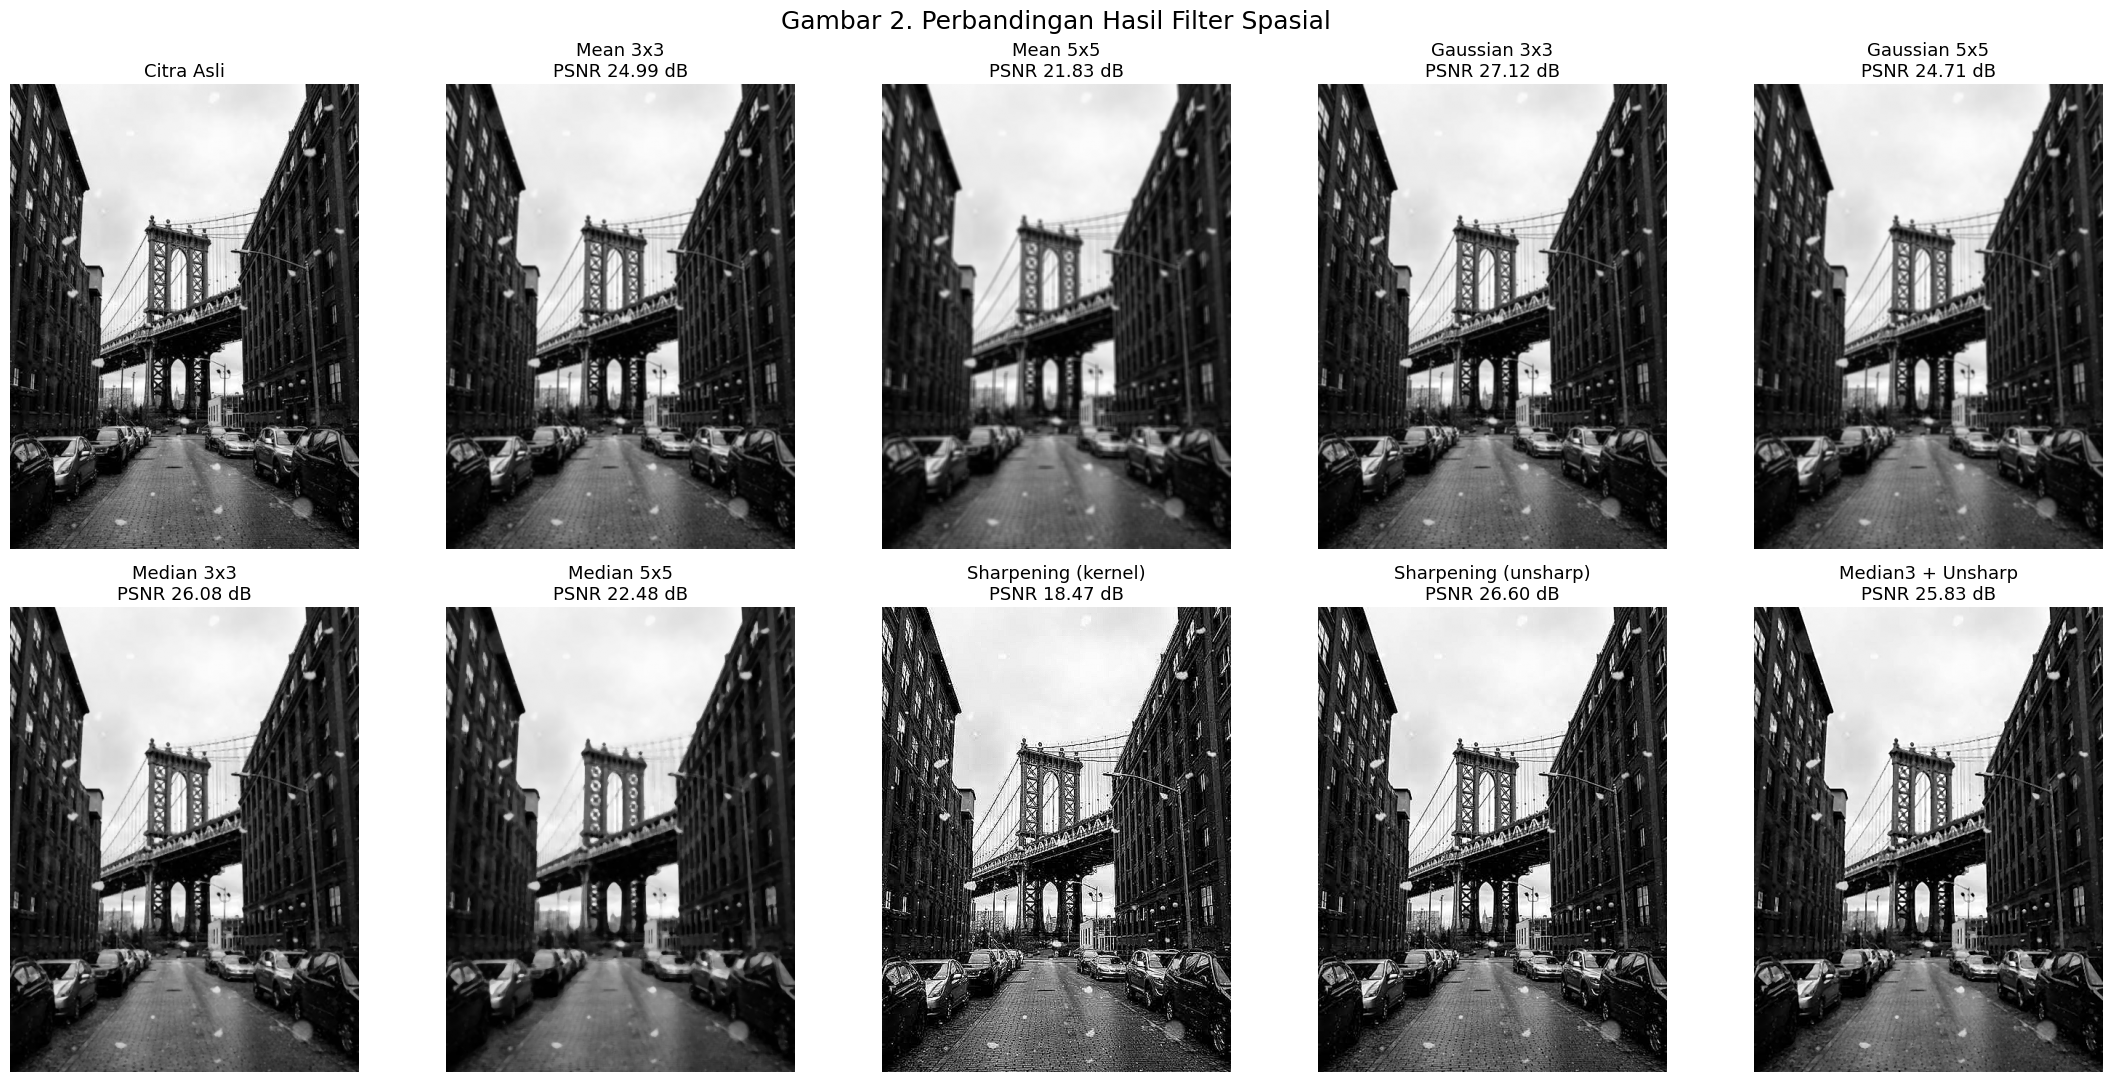

In [15]:
# 3. Perbandingan seluruh hasil (nilai PSNR ikut dicantumkan pada judul)
fig, axes = plt.subplots(2, 5, figsize=(22, 11))
for ax, (nama, im) in zip(axes.ravel(), hasil.items()):
    p = psnr(gray, im)
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(nama if nama == "Citra Asli" else f"{nama}\nPSNR {p:.2f} dB", fontsize=13)
    ax.axis("off")
plt.suptitle("Gambar 2. Perbandingan Hasil Filter Spasial", fontsize=18)
plt.tight_layout(); plt.savefig("g2_perbandingan.png", dpi=130); plt.show()

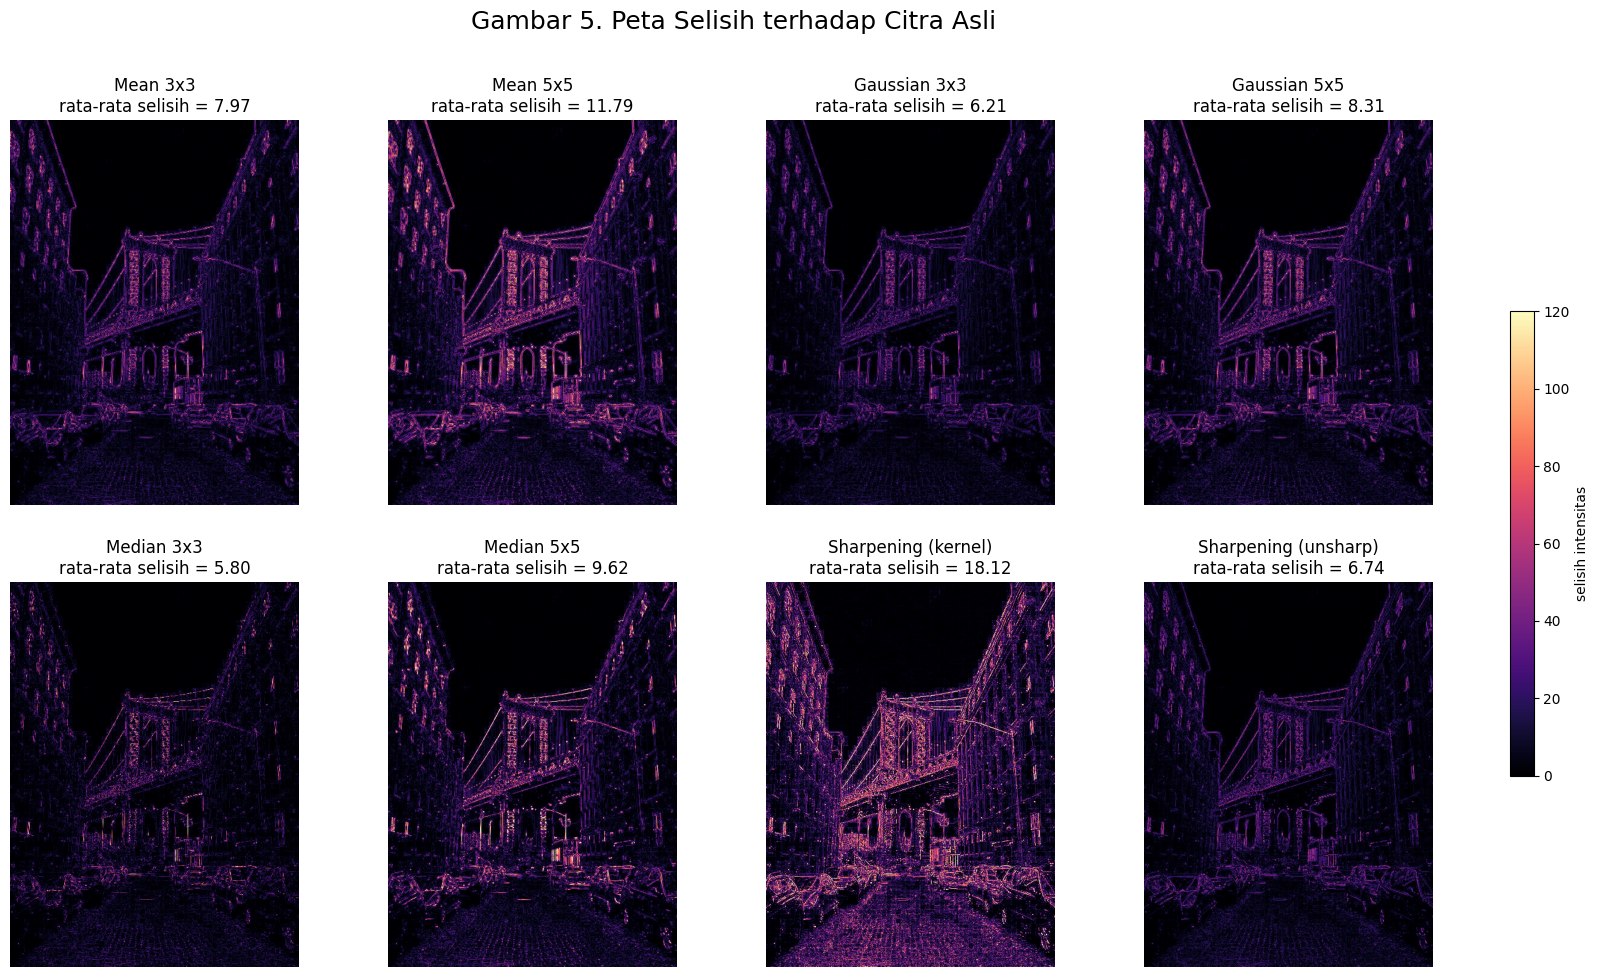

In [6]:
# 6. Peta selisih |hasil - asli|: terang = bagian yang paling berubah
fig, axes = plt.subplots(2, 4, figsize=(20, 11))
kunci = [k for k in hasil if k not in ("Citra Asli", "Median3 + Unsharp")]
for ax, nama in zip(axes.ravel(), kunci):
    selisih = np.abs(hasil[nama].astype(int) - gray.astype(int))
    im = ax.imshow(selisih, cmap="magma", vmin=0, vmax=120)
    ax.set_title(f"{nama}\nrata-rata selisih = {selisih.mean():.2f}", fontsize=12); ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.015, label="selisih intensitas")
plt.suptitle("Gambar 5. Peta Selisih terhadap Citra Asli", fontsize=18)
plt.savefig("g5_selisih.png", dpi=130, bbox_inches="tight"); plt.show()

Patch 5x5 berpusat di baris=230, kolom=260 (titik tepi terkuat)

[Citra Asli]
[[ 35  67  79  95 123]
 [ 11   0   0   0  12]
 [209 183 155 108  39]
 [240 235 255 239 111]
 [216 229 234 150  47]] 

[Mean 3x3]
[[ 63  65  71  76  79]
 [ 94  82  76  68  64]
 [161 143 131 102  73]
 [229 217 199 149  96]
 [234 224 190 148 106]] 

[Mean 5x5]
[[ 99  93  86  80  74]
 [129 125 113 103  93]
 [151 143 123 107  92]
 [179 165 138 114  88]
 [197 188 167 142 109]] 

[Gaussian 3x3]
[[ 56  65  73  81  89]
 [ 75  63  58  52  51]
 [172 152 137 105  66]
 [231 223 214 167  99]
 [233 225 199 145  98]] 

[Gaussian 5x5]
[[ 71  74  77  80  81]
 [ 96  87  80  72  66]
 [163 148 132 105  76]
 [216 205 183 143  97]
 [222 212 184 145 106]] 

[Median 3x3]
[[ 67  67  79  95  95]
 [ 67  67  79  79  44]
 [209 183 155 108  44]
 [235 229 229 150  65]
 [235 234 229 146 111]] 

[Median 5x5]
[[ 94  94  90  79  74]
 [120 120 120 108  91]
 [183 155 111  95  79]
 [216 215 150 111  65]
 [216 215 182 143 108]] 

[Sharpening (kerne

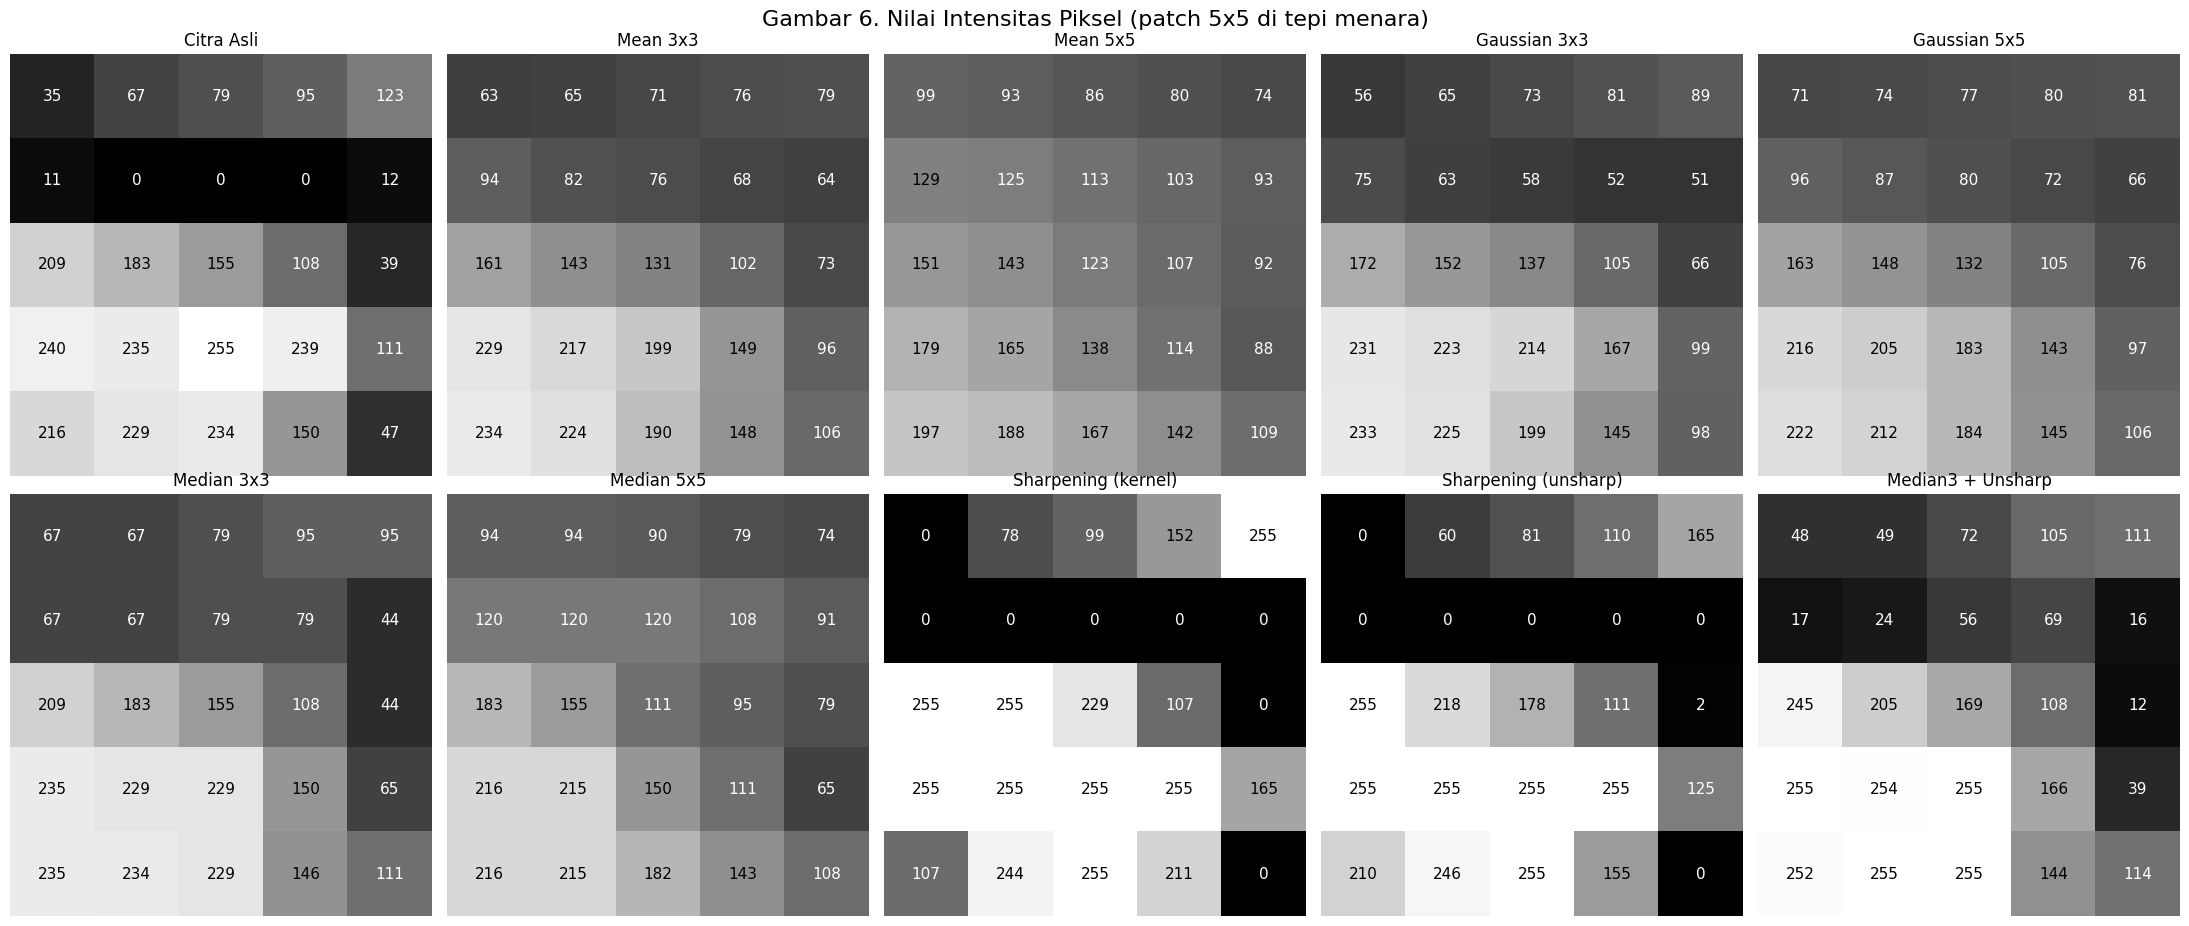

In [7]:
# 7. Nilai intensitas piksel setelah filter
#    Patch 5x5 diambil otomatis di titik tepi terkuat dalam area zoom (gradien Sobel maksimum)
gx = cv2.Sobel(gray.astype(np.float32), cv2.CV_32F, 1, 0)
gy = cv2.Sobel(gray.astype(np.float32), cv2.CV_32F, 0, 1)
grad = np.hypot(gx, gy)
y1, y2, x1, x2 = ZOOM
sub = grad[y1+3:y2-3, x1+3:x2-3]
py, px = np.unravel_index(np.argmax(sub), sub.shape)
py += y1 + 3; px += x1 + 3
print(f"Patch 5x5 berpusat di baris={py}, kolom={px} (titik tepi terkuat)\n")

for nama, im in hasil.items():
    print(f"[{nama}]")
    print(im[py-2:py+3, px-2:px+3], "\n")

# Versi gambar: angka intensitas ditulis di atas tiap piksel
fig, axes = plt.subplots(2, 5, figsize=(22, 9.5))
for ax, (nama, im) in zip(axes.ravel(), hasil.items()):
    p = im[py-2:py+3, px-2:px+3]
    ax.imshow(p, cmap="gray", vmin=0, vmax=255)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, int(p[i, j]), ha="center", va="center", fontsize=11,
                    color="white" if p[i, j] < 128 else "black")
    ax.set_title(nama, fontsize=12); ax.axis("off")
plt.suptitle("Gambar 6. Nilai Intensitas Piksel (patch 5x5 di tepi menara)", fontsize=16)
plt.tight_layout(); plt.savefig("g6_intensitas.png", dpi=130); plt.show()

In [8]:
# 8. Tabel metrik kuantitatif
def var_lap(im):  return cv2.Laplacian(im.astype(np.float64), cv2.CV_64F).var()
def kuat_tepi(im):
    y1, y2, x1, x2 = ZOOM
    a = im[y1:y2, x1:x2].astype(np.float32)
    return float(np.hypot(cv2.Sobel(a, cv2.CV_32F, 1, 0), cv2.Sobel(a, cv2.CV_32F, 0, 1)).mean())
tepi_asli = kuat_tepi(gray)
baris = []
for nama, im in hasil.items():
    baris.append({
        "Citra": nama,
        "Mean": im.mean(),
        "Std": im.std(),
        "Var Laplacian": var_lap(im),
        "PSNR (dB)": psnr(gray, im),
        "Tepi dipertahankan (%)": 100 * kuat_tepi(im) / tepi_asli,
    })
tabel = pd.DataFrame(baris).set_index("Citra").round(2)
print(tabel.to_string())

                        Mean    Std  Var Laplacian  PSNR (dB)  Tepi dipertahankan (%)
Citra                                                                                
Citra Asli             99.45  90.09        2624.02        inf                  100.00
Mean 3x3               99.45  87.76         214.78      24.99                   67.39
Mean 5x5               99.45  86.40          60.40      21.83                   47.96
Gaussian 3x3           99.48  88.11         327.19      27.12                   72.91
Gaussian 5x5           99.45  87.34         125.00      24.71                   61.16
Median 3x3             99.37  89.13         775.36      26.08                   73.11
Median 5x5             98.78  88.81         349.39      22.48                   52.96
Sharpening (kernel)   103.43  96.64       24574.79      18.47                  169.47
Sharpening (unsharp)  100.29  92.95        7378.47      26.60                  135.56
Median3 + Unsharp      99.50  91.03        2405.41    

PSNR terhadap citra asli (dB):
                Dengan noise  Mean 3x3  Mean 5x5  Gaussian 3x3  Gaussian 5x5  Median 3x3  Median 5x5
Gaussian s=25          21.28     23.63     21.43         24.76         23.65       23.67       21.92
Salt&Pepper 5%         17.22     22.43     21.08         22.98         22.77       25.71       22.39


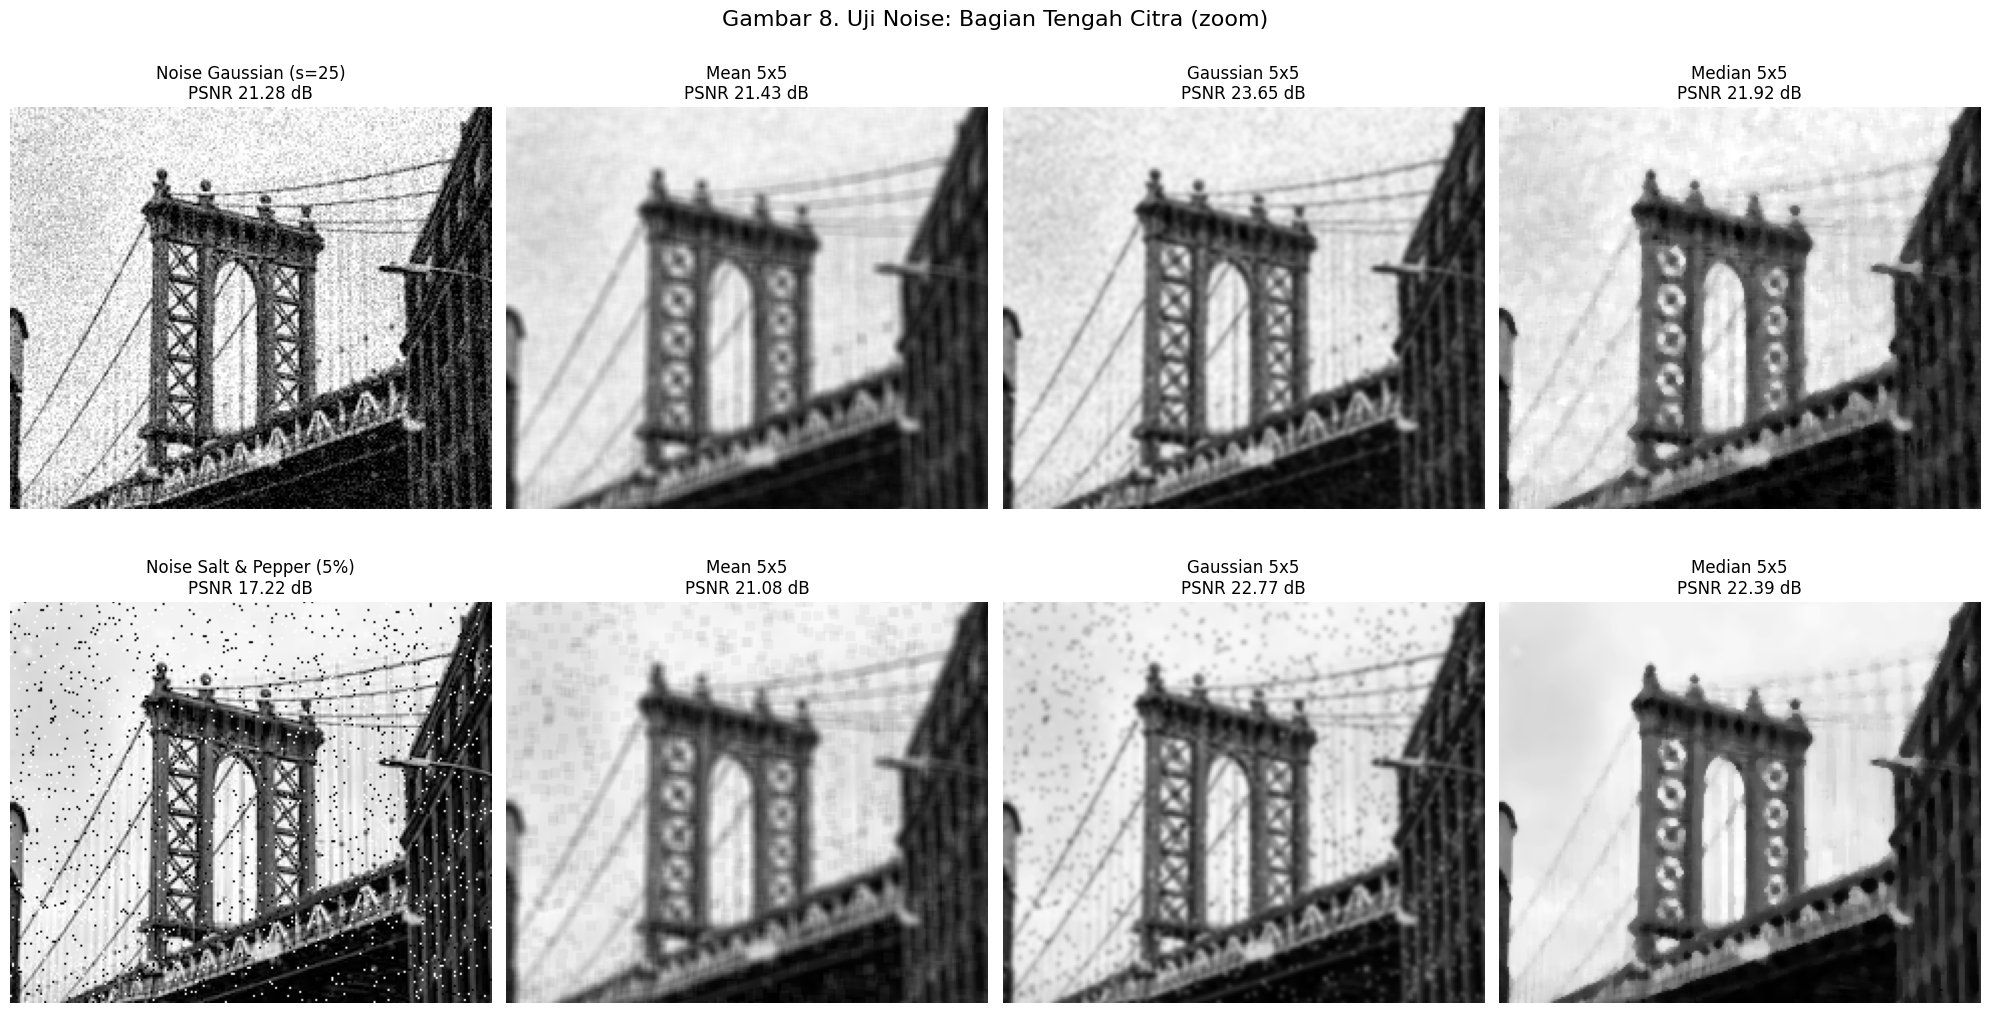

In [10]:
# 10. Uji ketahanan terhadap noise buatan (seed dikunci supaya bisa diulang)
# gn (Gaussian sigma=25) sudah dibuat di langkah 9
sp = gray.copy()                                                              # salt & pepper 5%
r = rng.random(gray.shape)
sp[r < 0.025] = 0
sp[r > 0.975] = 255

jenis_filter = {
    "Mean"    : lambda im, k: cv2.blur(im, (k, k)),
    "Gaussian": lambda im, k: cv2.GaussianBlur(im, (k, k), 0),
    "Median"  : lambda im, k: cv2.medianBlur(im, k),
}
rekap = {}
for label, noisy in {"Gaussian s=25": gn, "Salt&Pepper 5%": sp}.items():
    rekap[label] = {"Dengan noise": psnr(gray, noisy)}
    for fn, f in jenis_filter.items():
        for k in (3, 5):
            rekap[label][f"{fn} {k}x{k}"] = psnr(gray, f(noisy, k))
uji = pd.DataFrame(rekap).T.round(2)
print("PSNR terhadap citra asli (dB):")
print(uji.to_string())

fig, axes = plt.subplots(2, 4, figsize=(20, 11))
for baris_ax, (label, noisy) in zip(axes, {"Noise Gaussian (s=25)": gn, "Noise Salt & Pepper (5%)": sp}.items()):
    tampil = {label: noisy, "Mean 5x5": jenis_filter["Mean"](noisy, 5),
              "Gaussian 5x5": jenis_filter["Gaussian"](noisy, 5), "Median 5x5": jenis_filter["Median"](noisy, 5)}
    for ax, (nm, im) in zip(baris_ax, tampil.items()):
        ax.imshow(im[150:350, 120:360], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{nm}\nPSNR {psnr(gray, im):.2f} dB", fontsize=12); ax.axis("off")
plt.suptitle("Gambar 8. Uji Noise: Bagian Tengah Citra (zoom)", fontsize=16)
plt.tight_layout(); plt.savefig("g8_uji_noise.png", dpi=130); plt.show()